# Convergent cross mapping (CCM) entre TPM y EPM, con sustitutos de fase aleatoria

**Procedimiento:** Yuan, A. E. y Shou, W. (2020). *Data-driven causal analysis of observational time series: a synthesis.* bioRxiv 2020.08.03.233692 (preprint, "not certified by peer review"). Sección *Methods*, criterios de CCM. Los números de línea citados abajo son los de ese preprint.

**Idea del CCM** (Yuan y Shou, Fig. 8, siguiendo a Sugihara et al. 2012): si el TPM influye en el EPM, la historia del EPM guarda huellas del TPM. Entonces, con la variedad reconstruida a partir del EPM (vectores de sus valores pasados) se puede estimar el TPM. **Dirección analizada: la variedad del EPM estima el TPM**, que busca la huella de TPM → EPM.

**Datos:** los mismos de la transfer entropy, `../TE_R/data/series_diferencias_6h.csv`: primeras diferencias, rejilla de 6 h, tramo previo a la brecha. Se eliminan las 8 filas con NA (las mismas en todos los pares), lo que deja 880 observaciones.

## Pasos y su respaldo

| Paso | Qué se hace | Respaldo |
|---|---|---|
| Elegir $E$ y $\tau$ | Los que maximizan la predicción univariada a un paso del EPM (proyección simplex, *leave-one-out*), con rejilla $\tau=1..6$ y $E=1..6$ | Yuan y Shou, líneas 518–534 |
| Criterio 1 | La habilidad de cross-map $\rho$ debe ser positiva | Líneas 336–337 |
| **Criterio 2** | Se reemplaza el TPM por **1000 sustitutos de fase aleatoria de Ebisuzaki (1997)** y se recalcula $\rho$. $p$ = fracción de sustitutos con $\rho \ge \rho_{real}$. Pasa si $p\le0.05$ | Líneas 555–563 |
| Criterio 3 | La habilidad debe crecer con el tamaño de la biblioteca. **Procedimiento alternativo**: bibliotecas de 15 vectores al máximo, de 3 en 3; 50 bibliotecas sin reemplazo por tamaño; mediana de $\rho$ por tamaño; Kendall $\tau$ de una cola. Pasa si $\tau>0$ y $p\le0.05$ | Líneas 572–582, siguiendo a Chang et al. (2017) |
| Criterio 4 | Prueba de rezago: **no se usa**; Yuan y Shou reportan problemas con ella | Líneas 341–346 y Apéndice 1.12 |

## Desviaciones declaradas (no se pueden replicar con el software actual)

- **Bootstrap con reemplazo.** Yuan y Shou usan rEDM 1.5, que remuestrea bibliotecas **con reemplazo** para: (a) declarar significativa la predicción con que se elige $E$, (b) la prueba de robustez del criterio 1 y (c) el criterio 3 principal. Las versiones actuales (pyEDM 2.5.7 y rEDM 2.0.2) solo muestrean **sin** reemplazo. Por eso: (a) no se marca ningún par como "datos no aptos"; (b) el criterio 1 se evalúa sobre el valor estimado de $\rho$, sin prueba de robustez; (c) el criterio 3 usa el procedimiento alternativo de Kendall, que sí está documentado sin reemplazo.
- **Implementación de CCM de pyEDM:** se usa `legacy=True`, porque la implementación nueva de pyEDM 2.5.7 falla con numpy 1.26.

## Limitaciones conocidas

- Las series EPM están cuantizadas (pocos valores distintos), así que hay empates de vecinos en la variedad. Se usa el desempate propio de pyEDM, sin modificarlo.
- Los sustitutos de fase aleatoria conservan el espectro de potencia (Yuan y Shou, líneas 394–399) y suponen que el espectro no depende de la relación causal (línea 398). No descuentan un ciclo de 24 h compartido por ambas series (razonamiento propio, no verificado en un artículo).
- Yuan y Shou: *"there is no standard and automatic test procedure for CCM causality criteria"* (línea 362), y el desempeño del CCM *"quickly deteriorates with measurement or process noise"* (Fig. 9).

In [1]:
import os
import sys
import time
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.getcwd())
import ccm_funciones as cf

ARCHIVO_DATOS = Path('../TE_R/data/series_diferencias_6h.csv')
ARCHIVO_E_TAU = Path('data/ccm_E_tau_por_sensor.csv')
ARCHIVO_RESULTADOS = Path('data/ccm_resultados_56_pares.csv')
FIGURAS = Path('figuras')
FIGURAS.mkdir(exist_ok=True)
SEMILLA = 2026
PROCESOS = 14

series_tpm = ['POT(1)', 'POT(2)', 'POT(3)', 'POT(4)', 'POT(5)', 'POT(6)', 'POT(7)',
              'Tilt(1)', 'Tilt(2)', 'Tilt(3)', 'Tilt(4)', 'Tilt(5)', 'Tilt(6)', 'Tilt(7)']
series_epm = ['Sensor 1 (5m)', 'Sensor 2 (10m)', 'Sensor 3 (5m)', 'Sensor 4 (10m)']

datos = pd.read_csv(ARCHIVO_DATOS)
print('Filas:', len(datos), '| con NA:', datos.isna().any(axis=1).sum())
datos = datos.dropna().reset_index(drop=True)
print('Filas usadas:', len(datos))
print(f'Sustitutos por par: {cf.N_SUSTITUTOS}  |  bibliotecas por tamano: {cf.MUESTRAS_POR_L}')

Filas: 888 | con NA: 8
Filas usadas: 880
Sustitutos por par: 1000  |  bibliotecas por tamano: 50


## 1. Elección de $E$ y $\tau$ para cada sensor EPM

Es la variedad que se usa para estimar el TPM, así que $E$ y $\tau$ dependen solo del EPM (Yuan y Shou, líneas 518–534).

In [2]:
if ARCHIVO_E_TAU.exists():
    tabla_E = pd.read_csv(ARCHIVO_E_TAU)
else:
    filas = []
    for epm in series_epm:
        E, tau, rho_p, _ = cf.elegir_E_tau(datos[epm].to_numpy())
        filas.append({'EPM': epm, 'E': E, 'tau': tau, 'rho_prediccion_1_paso': rho_p})
    tabla_E = pd.DataFrame(filas)
    tabla_E.to_csv(ARCHIVO_E_TAU, index=False)
tabla_E

,EPM,E,tau,rho_prediccion_1_paso
0,Sensor 1 (5m),6,1,0.516829
1,Sensor 2 (10m),5,1,0.499315
2,Sensor 3 (5m),3,1,0.480509
3,Sensor 4 (10m),3,1,0.280955


## 2. Batería: 56 pares

Cada par: habilidad real, criterio 2 (1000 sustitutos) y criterio 3 (Kendall). Los pares se reparten entre varios procesos. Tarda unos 20 minutos. Los resultados se guardan en `data/ccm_resultados_56_pares.csv`; si el archivo existe, se carga en vez de recalcular.

In [3]:
if ARCHIVO_RESULTADOS.exists():
    res = pd.read_csv(ARCHIVO_RESULTADOS)
    print(f'Cargado desde cache: {ARCHIVO_RESULTADOS}')
else:
    params = tabla_E.set_index('EPM')
    tareas = []
    for i, (epm, tpm) in enumerate([(e, t) for e in series_epm for t in series_tpm]):
        tareas.append((epm, tpm, datos[epm].to_numpy(), datos[tpm].to_numpy(),
                       int(params.loc[epm, 'E']), int(params.loc[epm, 'tau']), SEMILLA + i))
    t0 = time.time()
    with ProcessPoolExecutor(max_workers=PROCESOS) as ex:
        res = pd.DataFrame(list(ex.map(cf.procesar_par, tareas)))
    print(f'Tiempo: {(time.time() - t0) / 60:.1f} min')
    res.to_csv(ARCHIVO_RESULTADOS, index=False)
res.head()

Tiempo: 40.2 min


,EPM,TPM,E,tau,n,rho,criterio1_rho_positivo,p_sustitutos,criterio2_significativo,rho_sust_p95,kendall_tau,p_kendall,criterio3_converge,rho_Lmin,rho_Lmax
0,Sensor 1 (5m),POT(1),6,1,880,0.001727,True,0.481,False,0.079327,-0.144013,1.427222e-04,False,0.02660,0.001720
1,Sensor 1 (5m),POT(2),6,1,880,-0.010177,False,0.527,False,0.072200,-0.632767,8.968424e-58,False,0.00395,-0.010100
2,Sensor 1 (5m),POT(3),6,1,880,0.399890,True,0.000,True,0.138722,-0.005995,4.398324e-01,False,0.33555,0.400185
3,Sensor 1 (5m),POT(4),6,1,880,0.347105,True,0.000,True,0.117695,0.855907,6.171365e-104,True,0.23502,0.344650
4,Sensor 1 (5m),POT(5),6,1,880,0.010427,True,0.404,False,0.071923,0.649065,1.083553e-60,True,0.00767,0.010525


## 3. Resumen

- **Pasa el CCM** = criterio 1 **y** criterio 2 **y** criterio 3.
- **Referencia de azar para el criterio 2:** si no hubiera ninguna relación, se esperarían $56\times0.05=2.8$ pares con $p\le0.05$.
- **Corrección por comparaciones múltiples (Benjamini-Hochberg, FDR 5 %)** sobre los $p$ del criterio 2, como la describe y usa Kugiumtzis (2013, sec. 4).
- Con 1000 sustitutos, un $p=0$ significa que ninguno alcanzó la $\rho$ real: se reporta como $p<1/1000$.

In [4]:
def benjamini_hochberg(p, alfa=0.05):
    p = np.asarray(p)
    m = len(p)
    orden = np.argsort(p, kind='stable')
    k = 0
    for i in range(m, 0, -1):
        if p[orden[i - 1]] <= i * alfa / m:
            k = i
            break
    sig = np.zeros(m, dtype=bool)
    sig[orden[:k]] = True
    return sig


res['pasa_ccm'] = res['criterio1_rho_positivo'] & res['criterio2_significativo'] & res['criterio3_converge']
res['criterio2_BH'] = benjamini_hochberg(res['p_sustitutos'])
res['pasa_ccm_BH'] = res['criterio1_rho_positivo'] & res['criterio2_BH'] & res['criterio3_converge']

pd.DataFrame({
    'pares': [len(res)],
    'criterio 1 (rho > 0)': [int(res['criterio1_rho_positivo'].sum())],
    'criterio 2 (p <= 0.05)': [int(res['criterio2_significativo'].sum())],
    'criterio 2 con BH': [int(res['criterio2_BH'].sum())],
    'criterio 3 (converge)': [int(res['criterio3_converge'].sum())],
    'pasa CCM (1 y 2 y 3)': [int(res['pasa_ccm'].sum())],
    'pasa CCM con BH': [int(res['pasa_ccm_BH'].sum())],
    'esperado por azar (criterio 2)': [round(len(res) * 0.05, 1)],
})

,pares,criterio 1 (rho > 0),criterio 2 (p <= 0.05),criterio 2 con BH,criterio 3 (converge),pasa CCM (1 y 2 y 3),pasa CCM con BH,esperado por azar (criterio 2)
0,56,47,29,27,38,20,19,2.8


In [5]:
cols = ['EPM', 'TPM', 'E', 'tau', 'rho', 'p_sustitutos', 'kendall_tau', 'p_kendall', 'pasa_ccm', 'pasa_ccm_BH']
res[res['criterio2_significativo']][cols].sort_values(['EPM', 'rho'], ascending=[True, False]).round(4).reset_index(drop=True)

,EPM,TPM,E,tau,rho,p_sustitutos,kendall_tau,p_kendall,pasa_ccm,pasa_ccm_BH
0,Sensor 1 (5m),Tilt(4),6,1,0.5922,0.000,0.5000,0.0000,True,True
1,Sensor 1 (5m),POT(6),6,1,0.5830,0.000,0.8678,0.0000,True,True
2,Sensor 1 (5m),Tilt(5),6,1,0.5362,0.000,0.0933,0.0092,True,True
3,Sensor 1 (5m),Tilt(3),6,1,0.4198,0.000,0.8872,0.0000,True,True
4,Sensor 1 (5m),POT(3),6,1,0.3999,0.000,-0.0060,0.4398,False,False
5,Sensor 1 (5m),POT(7),6,1,0.3490,0.000,0.6555,0.0000,True,True
6,Sensor 1 (5m),POT(4),6,1,0.3471,0.000,0.8559,0.0000,True,True
7,Sensor 1 (5m),Tilt(6),6,1,0.3075,0.000,0.0184,0.3211,False,False
8,Sensor 1 (5m),Tilt(2),6,1,0.2541,0.000,-0.6053,0.0000,False,False
9,Sensor 1 (5m),Tilt(1),6,1,0.1662,0.002,-0.5068,0.0000,False,False


## 4. Mapas de calor

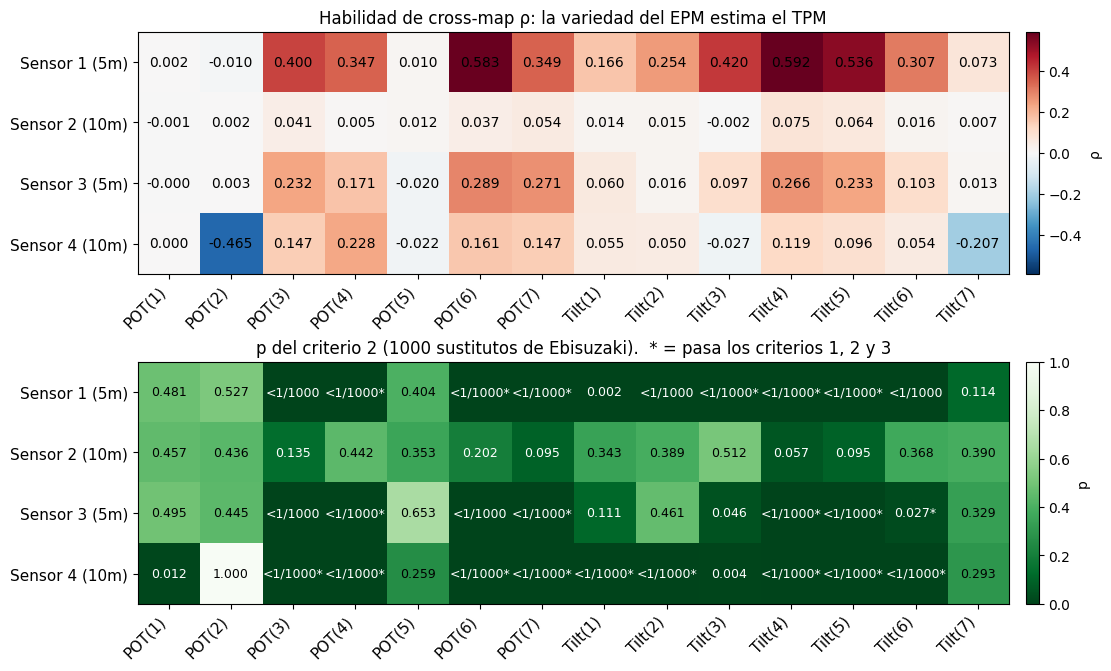

In [6]:
def matriz(col):
    return res.pivot(index='EPM', columns='TPM', values=col).loc[series_epm, series_tpm]


fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.6), constrained_layout=True)
m = matriz('rho')
im = a1.imshow(m.values, cmap='RdBu_r', vmin=-max(abs(m.values.min()), m.values.max()),
               vmax=max(abs(m.values.min()), m.values.max()), aspect='auto')
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        a1.text(j, i, f'{m.values[i, j]:.3f}', ha='center', va='center', fontsize=10)
a1.set_title('Habilidad de cross-map ρ: la variedad del EPM estima el TPM', fontsize=12)
plt.colorbar(im, ax=a1, fraction=0.025, pad=0.02, label='ρ')

pm = matriz('p_sustitutos')
paso = matriz('pasa_ccm')
im = a2.imshow(pm.values, cmap='Greens_r', vmin=0, vmax=1, aspect='auto')
for i in range(pm.shape[0]):
    for j in range(pm.shape[1]):
        v = pm.values[i, j]
        txt = ('<1/1000' if v == 0 else f'{v:.3f}') + ('*' if paso.values[i, j] else '')
        a2.text(j, i, txt, ha='center', va='center', fontsize=9, color='white' if v < 0.25 else 'black')
a2.set_title(f'p del criterio 2 ({cf.N_SUSTITUTOS} sustitutos de Ebisuzaki).  * = pasa los criterios 1, 2 y 3', fontsize=12)
plt.colorbar(im, ax=a2, fraction=0.025, pad=0.02, label='p')
for a in (a1, a2):
    a.set_xticks(range(len(series_tpm)), series_tpm, rotation=45, ha='right', fontsize=11)
    a.set_yticks(range(len(series_epm)), series_epm, fontsize=11)
fig.savefig(FIGURAS / 'ccm_heatmaps.png', dpi=200)
plt.show()